# EDA: duration, hourly demand, utilization 

In [ ]:
import sys
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                     if (p / 'data' / 'processed' / 'Charging_Data_clean.csv').is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Could not find data/processed/Charging_Data_clean.csv from the current directory.')
sys.path.insert(0, str(PROJECT_ROOT / 'team' / 'mariam_availability'))
from src.occupancy import hourly_busy

TAB = PROJECT_ROOT / 'team' / 'mariam_availability' / 'reports' / 'tables'
TAB.mkdir(parents=True, exist_ok=True)
CLEAN_DATA_PATH = PROJECT_ROOT / 'data' / 'processed' / 'Charging_Data_clean.csv'
df = pd.read_csv(CLEAN_DATA_PATH, parse_dates=['start', 'end'])
df['hour'] = df['start'].dt.hour
df['dow'] = df['start'].dt.dayofweek
df['date'] = df['start'].dt.date
len(df)

## 1. Duration

In [ ]:
df['duration_min'].describe(percentiles=[.01,.05,.25,.5,.75,.95,.99]).round(1)

In [14]:
print('sessions over 12h:', (df['duration_min'] > 720).sum())
df.groupby('is_abnormal')['duration_min'].agg(['count','median','mean']).round(1)

sessions over 12h: 1328


,count,median,mean
is_abnormal,,,
0,359083,39.3,61.5
1,81889,2.2,25.1


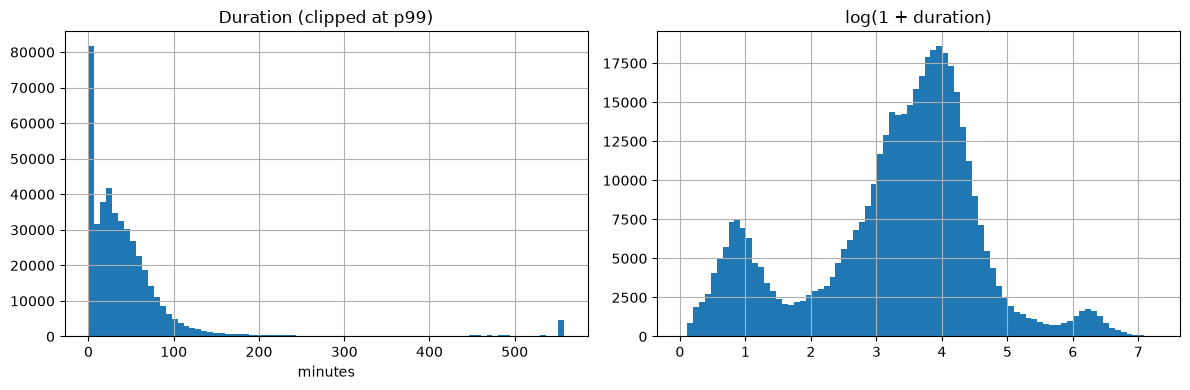

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df['duration_min'].clip(upper=df['duration_min'].quantile(.99)).hist(bins=80, ax=ax[0])
ax[0].set_title('Duration (clipped at p99)'); ax[0].set_xlabel('minutes')
np.log1p(df['duration_min']).hist(bins=80, ax=ax[1])
ax[1].set_title('log(1 + duration)')
plt.tight_layout(); plt.show()

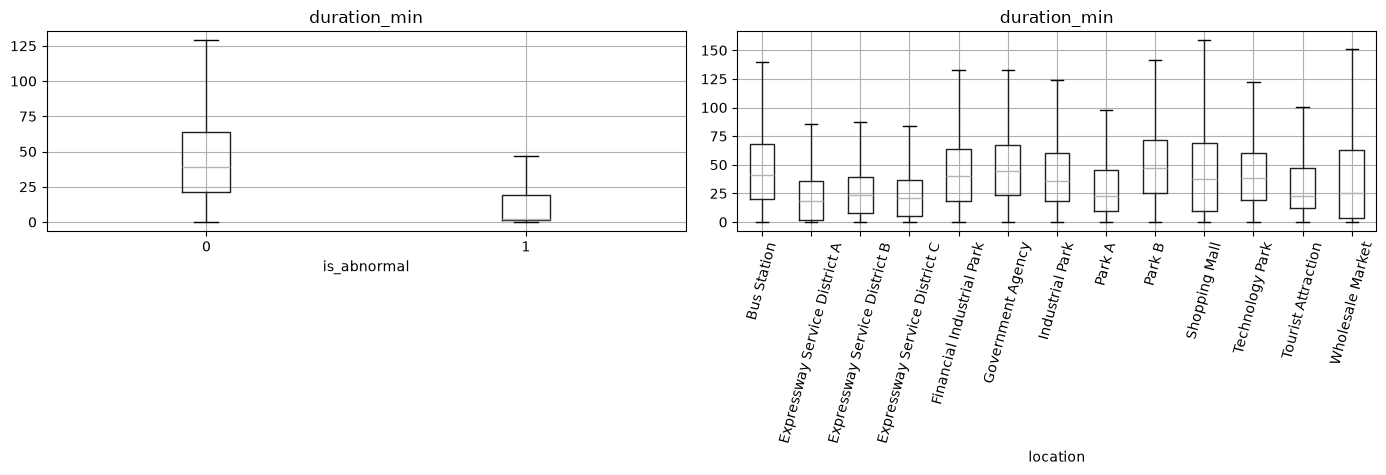

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
df.boxplot(column='duration_min', by='is_abnormal', ax=ax[0], showfliers=False)
df.boxplot(column='duration_min', by='location', ax=ax[1], showfliers=False)
ax[1].tick_params(axis='x', rotation=75)
plt.suptitle(''); plt.tight_layout(); plt.show()

In [17]:
per_charger = df.groupby('charger_id')['duration_min'].agg(['count','median','std'])
print(per_charger['median'].describe().round(1))
per_charger.to_csv(TAB / 'duration_per_charger.csv')

count    92.0
mean     32.8
std      10.7
min       7.6
25%      23.2
50%      33.9
75%      42.8
max      51.4
Name: median, dtype: float64


## Duration correlations
Spearman correlations show monotonic relationships with duration; identifiers and timestamps are excluded.

In [ ]:
correlation_candidates = [
    c for c in ["duration_min", "energy_kwh", "temp_c", "humidity", "precip_mm",
                "is_abnormal", "is_full_charge", "is_user_stop", "is_nonsystem_fault",
                "is_system_issue", "is_EV_fault", "is_other_fault"]
    if c in df and pd.api.types.is_numeric_dtype(df[c])
]
correlations = df[correlation_candidates].corr(method="spearman", min_periods=100)
correlations.to_csv(TAB / "duration_correlations.csv")
correlations["duration_min"].sort_values(ascending=False).to_frame("spearman_with_duration")

The right tail is heavy, so use MAE and consider log duration or clipping. Abnormal sessions are very short, so train on `is_abnormal == 0`. Per charger medians range widely, so charger identity is a strong feature.

## 2. Hourly demand per location

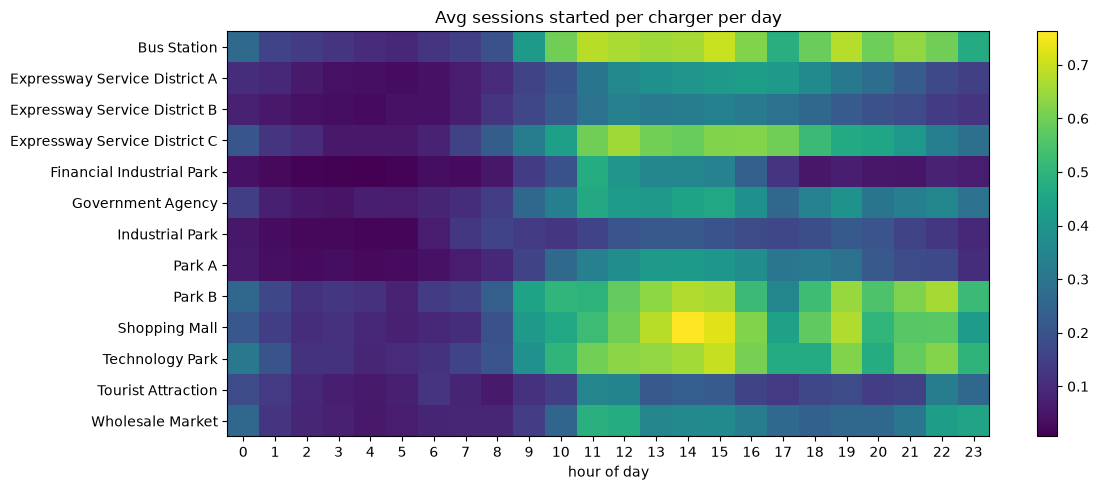

In [18]:
n_days = df['date'].nunique()
chargers_per_loc = df.groupby('location')['charger_id'].nunique()
dem = df.groupby(['location','hour']).size().unstack(fill_value=0) / n_days
dem_pc = dem.div(chargers_per_loc, axis=0)
dem_pc.round(3).to_csv(TAB / 'hourly_demand_per_charger_by_location.csv')

fig, ax = plt.subplots(figsize=(12, 5))
im = ax.imshow(dem_pc.values, aspect='auto', cmap='viridis')
ax.set_yticks(range(len(dem_pc))); ax.set_yticklabels(dem_pc.index)
ax.set_xticks(range(24)); ax.set_xlabel('hour of day')
ax.set_title('Avg sessions started per charger per day')
plt.colorbar(im); plt.tight_layout(); plt.show()

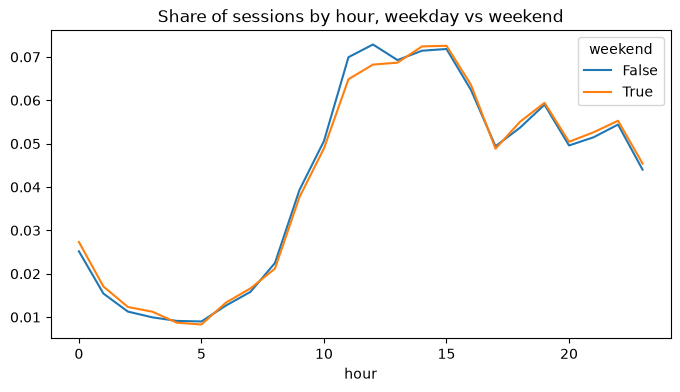

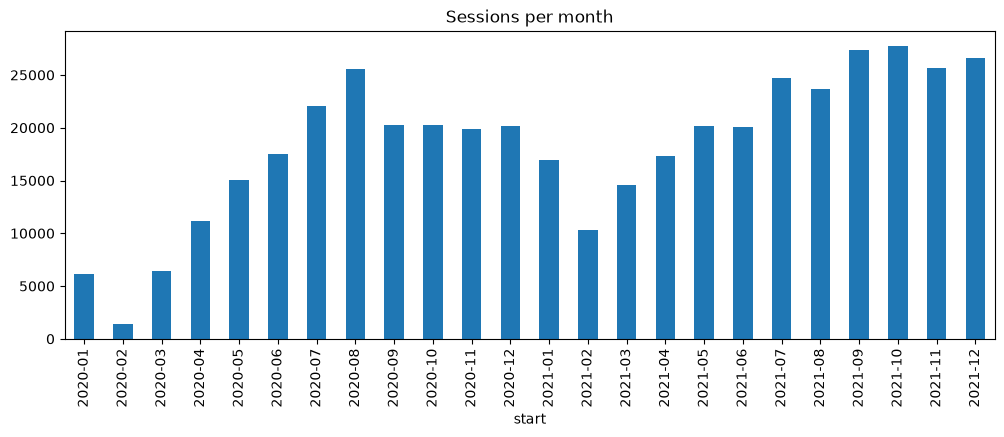

In [19]:
wk = df.assign(weekend=df['dow'] >= 5).groupby(['weekend','hour']).size().unstack(0)
(wk / wk.sum()).plot(figsize=(8, 4), title='Share of sessions by hour, weekday vs weekend')
plt.show()
df.groupby(df['start'].dt.to_period('M')).size().plot(kind='bar', figsize=(12, 4), title='Sessions per month')
plt.show()

Demand differs by site type (bus station vs expressway vs park) and by hour. Volume grew over time, so a chronological split puts more data in the later months. Hour, weekday and location should all be features.

## 3. Utilization per charger

count    92.000
mean      0.252
std       0.151
min       0.021
25%       0.120
50%       0.206
75%       0.399
max       0.584
Name: utilization, dtype: float64


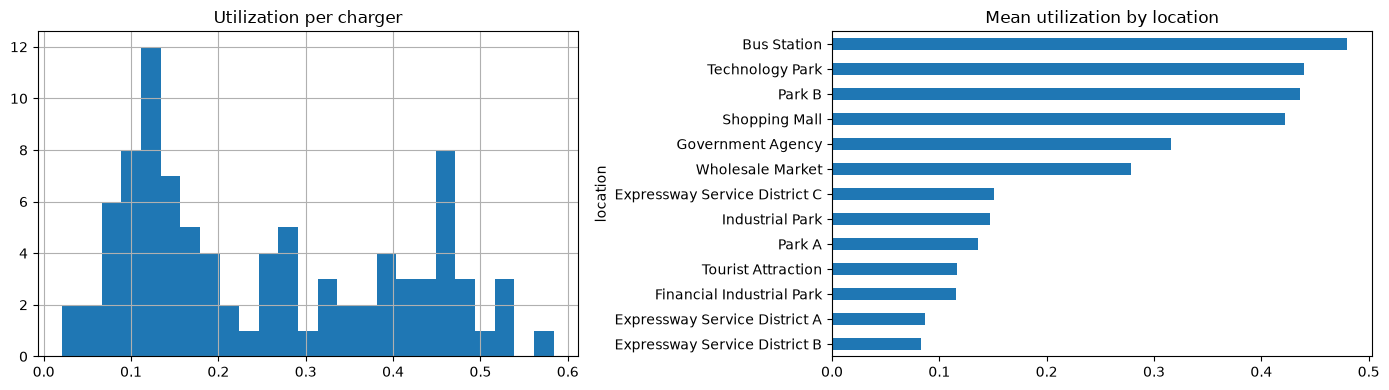

In [20]:
span = (df.groupby('charger_id')['end'].max() - df.groupby('charger_id')['start'].min()).dt.total_seconds() / 60
util = (df.groupby('charger_id')['duration_min'].sum() / span).rename('utilization').to_frame()
util = util.join(df.groupby('charger_id')[['location','district']].first())
util.sort_values('utilization').to_csv(TAB / 'utilization_per_charger.csv')
print(util['utilization'].describe().round(3))

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
util['utilization'].hist(bins=25, ax=ax[0]); ax[0].set_title('Utilization per charger')
util.groupby('location')['utilization'].mean().sort_values().plot(kind='barh', ax=ax[1], title='Mean utilization by location')
plt.tight_layout(); plt.show()

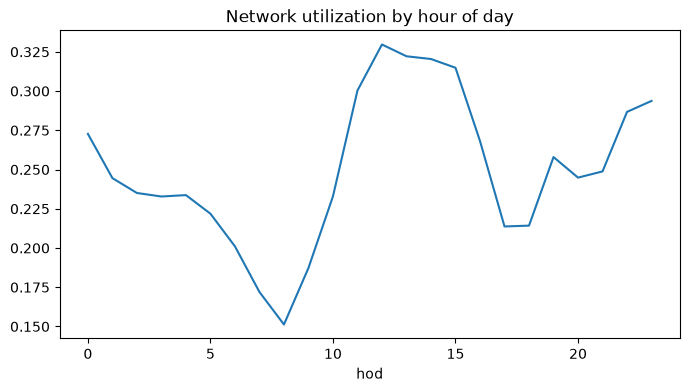

hod
0     0.273
1     0.245
2     0.235
3     0.233
4     0.234
5     0.222
6     0.201
7     0.172
8     0.151
9     0.187
10    0.233
11    0.300
12    0.330
13    0.322
14    0.320
15    0.315
16    0.268
17    0.214
18    0.214
19    0.258
20    0.245
21    0.249
22    0.287
23    0.294
dtype: float64

In [21]:
busy = hourly_busy(df)
busy['hod'] = busy['hour'].dt.hour
n_charger_hours = busy.groupby('hod')['hour'].nunique() * df['charger_id'].nunique()
util_hod = busy.groupby('hod')['busy_min'].sum() / (n_charger_hours * 60)
util_hod.plot(figsize=(8, 4), title='Network utilization by hour of day'); plt.show()
util_hod.round(3)

In [22]:
loc_map = df.groupby('charger_id')['location'].first()
b = busy.assign(location=busy['charger_id'].map(loc_map))
peak = b.groupby(['location','hour'])['busy_min'].sum().div(
    chargers_per_loc.reindex(b['location'].unique()).rename_axis('location') * 60, level='location')
print('share of location hours with average busy share > 0.9:', round((peak > 0.9).mean(), 4))
peak.sort_values(ascending=False).head(15).to_csv(TAB / 'top_peak_location_hours.csv')
peak.sort_values(ascending=False).head(15)

share of location hours with average busy share > 0.9: 0.0136


location           hour               
Technology Park    2020-05-28 04:00:00    1.0
Government Agency  2021-08-02 06:00:00    1.0
                   2021-08-02 04:00:00    1.0
                   2021-08-02 05:00:00    1.0
                   2021-08-02 03:00:00    1.0
Park B             2021-10-25 04:00:00    1.0
                   2021-10-25 00:00:00    1.0
Wholesale Market   2021-10-16 02:00:00    1.0
Government Agency  2021-07-16 04:00:00    1.0
                   2021-07-16 03:00:00    1.0
                   2021-07-16 02:00:00    1.0
Park B             2021-10-25 03:00:00    1.0
Government Agency  2021-07-16 01:00:00    1.0
                   2021-07-03 03:00:00    1.0
                   2021-07-03 04:00:00    1.0
dtype: float64

**Reading it:** average utilization is about 25%, so chargers are free most of the time. Waiting only happens in rare peak windows. Build your replay around those windows, otherwise every policy shows zero wait.